# Ewaluacja metod detekcji punktów

Porównanie metody bazowej z metodą `line_aware` na podstawie metryki F1.

> **Cel analizy:** sprawdzić, jak typ wykresu i jego właściwości wpływają na skuteczność obu metod detekcji.

## 1. Zakres i plan analizy

Analiza obejmuje cztery etapy:

1. **Przygotowanie danych** — utworzenie jednej tabeli z metrykami obu metod dla każdego obrazu.
2. **Zdefiniowanie wizualizacji** — przedstawienie średniej wartości F1 w grupach wyznaczonych przez pojedyncze cechy obrazów.
3. **Ocena metody bazowej** — osobno dla wszystkich wykresów, wykresów punktowych i wykresów punktowo-liniowych.
4. **Ocena metody `line_aware`** — w tych samych grupach, aby umożliwić bezpośrednie porównanie.

## 2. Przygotowanie danych i wspólne narzędzia

In [1]:
import sys
from pathlib import Path

project_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "src" / "scatter_detection").exists()
)
sys.path.insert(0, str(project_root / "src"))

from scatter_detection.evaluation.data_preparation import prepare_evaluation_dataframe


image_summary = prepare_evaluation_dataframe()
image_summary.head()

image_id,detection_method,tolerance,total_ground_truth,detected_points,true_positives,false_positives,false_negatives,precision,recall,f1,mean_distance,rmse_distance,function_type,grid_lines,x_sampling_strategy,marker_size,plot_style,width,height,n_generated,n_visible
str,str,f64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,str,bool,str,i64,str,i64,i64,i64,i64
"""plot_001""","""baseline""",0.15,84,64,64,0,20,1.0,0.761905,0.864865,0.024149,0.033334,"""polynomials""",false,"""uniform""",23,"""scatter_plot""",868,881,85,84
"""plot_001""","""line_aware""",0.15,84,69,69,0,15,1.0,0.821429,0.901961,0.026597,0.036981,"""polynomials""",false,"""uniform""",23,"""scatter_plot""",868,881,85,84
"""plot_002""","""baseline""",0.15,35,32,32,0,3,1.0,0.914286,0.955224,0.015798,0.016736,"""polynomials""",false,"""uniform""",29,"""scatter_plot""",804,681,36,35
"""plot_002""","""line_aware""",0.15,35,32,32,0,3,1.0,0.914286,0.955224,0.015798,0.016736,"""polynomials""",false,"""uniform""",29,"""scatter_plot""",804,681,36,35
"""plot_003""","""baseline""",0.15,94,82,82,0,12,1.0,0.87234,0.931818,0.024132,0.033602,"""polynomials""",false,"""uniform""",9,"""scatter_plot""",647,511,97,94


Tabela `image_summary` zawiera jeden wiersz dla każdej pary `(obraz, metoda)`. Oprócz metryk detekcji przechowuje również metadane obrazu, dzięki czemu wyniki można agregować według wybranych cech.

In [2]:
import matplotlib.pyplot as plt
import numpy as np


GROUPING_COLUMNS = [
    "x_sampling_strategy",
    "marker_size",
    "plot_style",
    "function_type",
    "grid_lines",
]


def _plot_grouped_f1(axis, grouped, grouping_column, color):
    labels = grouped[grouping_column].cast(pl.String).to_list()
    values = grouped["mean_f1"].to_list()
    mean_f1 = grouped["mean_f1"].mean()
    standard_deviation = grouped["mean_f1"].std() or 0.0

    if grouping_column == "marker_size":
        axis.plot(
            labels,
            values,
            marker="o",
            linewidth=2.5,
            markersize=7,
            color=color,
        )
        axis.set_xticks(labels)
        axis.set_xticklabels(labels)
        axis.set_xlabel("marker_size")
        axis.set_ylabel("Średnie F1")
        axis.set_ylim(0, 1.08)
        axis.axhline(mean_f1, color="black", linestyle="--", alpha=0.7)
        axis.axhspan(
            mean_f1 - standard_deviation,
            mean_f1 + standard_deviation,
            color="gray",
            alpha=0.2,
        )
        axis.annotate(
            f"{mean_f1:.2f}",
            xy=(1, mean_f1),
            xycoords=axis.get_yaxis_transform(),
            xytext=(-5, 5),
            textcoords="offset points",
            ha="right",
            fontsize=9,
        )
        return

    positions = np.arange(len(labels))
    bars = axis.barh(
        positions,
        values,
        color=color,
        alpha=0.85,
        edgecolor="white",
    )
    axis.set_yticks(positions, labels)
    axis.set_xlabel("Średnie F1")
    axis.set_xlim(0, 1.08)
    axis.axvline(mean_f1, color="black", linestyle="--", alpha=0.7)
    axis.axvspan(
        mean_f1 - standard_deviation,
        mean_f1 + standard_deviation,
        color="gray",
        alpha=0.2,
    )
    axis.annotate(
        f"{mean_f1:.2f}",
        xy=(mean_f1, 1),
        xycoords=axis.get_xaxis_transform(),
        xytext=(5, -5),
        textcoords="offset points",
        ha="left",
        va="top",
        fontsize=9,
    )
    axis.set_title(grouping_column.replace("_", " ").title(), pad=10)
    axis.spines[["top", "right", "left"]].set_visible(False)

    for bar, value in zip(bars, values):
        axis.text(
            value + 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            fontsize=9,
        )


def plot_mean_f1_by_grouping_column(results):
    'Show mean F1 grouped by each configured image characteristic.'
    plt.style.use("seaborn-v0_8-whitegrid")
    figure = plt.figure(figsize=(18, 11), constrained_layout=True)
    grid = figure.add_gridspec(2, 3)
    axes = [
        figure.add_subplot(grid[0, 0]),
        figure.add_subplot(grid[0, 1:]),
        figure.add_subplot(grid[1, 0]),
        figure.add_subplot(grid[1, 1]),
        figure.add_subplot(grid[1, 2]),
    ]
    colors = plt.cm.viridis(
        np.linspace(0.2, 0.85, len(GROUPING_COLUMNS))
    )

    for axis, grouping_column, color in zip(
        axes, GROUPING_COLUMNS, colors
    ):
        grouped = (
            results.group_by(grouping_column)
            .agg(mean_f1=pl.col("f1").mean())
            .sort(grouping_column)
        )
        _plot_grouped_f1(axis, grouped, grouping_column, color)
        axis.grid(axis="x", alpha=0.25)
        axis.grid(axis="y", visible=False)

    figure.suptitle(
        "Średnia wartość F1 według pojedynczych kryteriów",
        fontsize=16,
        fontweight="bold",
    )
    plt.show()

## 3. Metoda bazowa

Metoda bazowa nie została zaprojektowana do rozdzielania punktów od linii łączących.

In [3]:
import polars as pl


baseline_results = image_summary.filter(
    pl.col("detection_method") == "baseline"
)

### 3.1. Wyniki zbiorcze

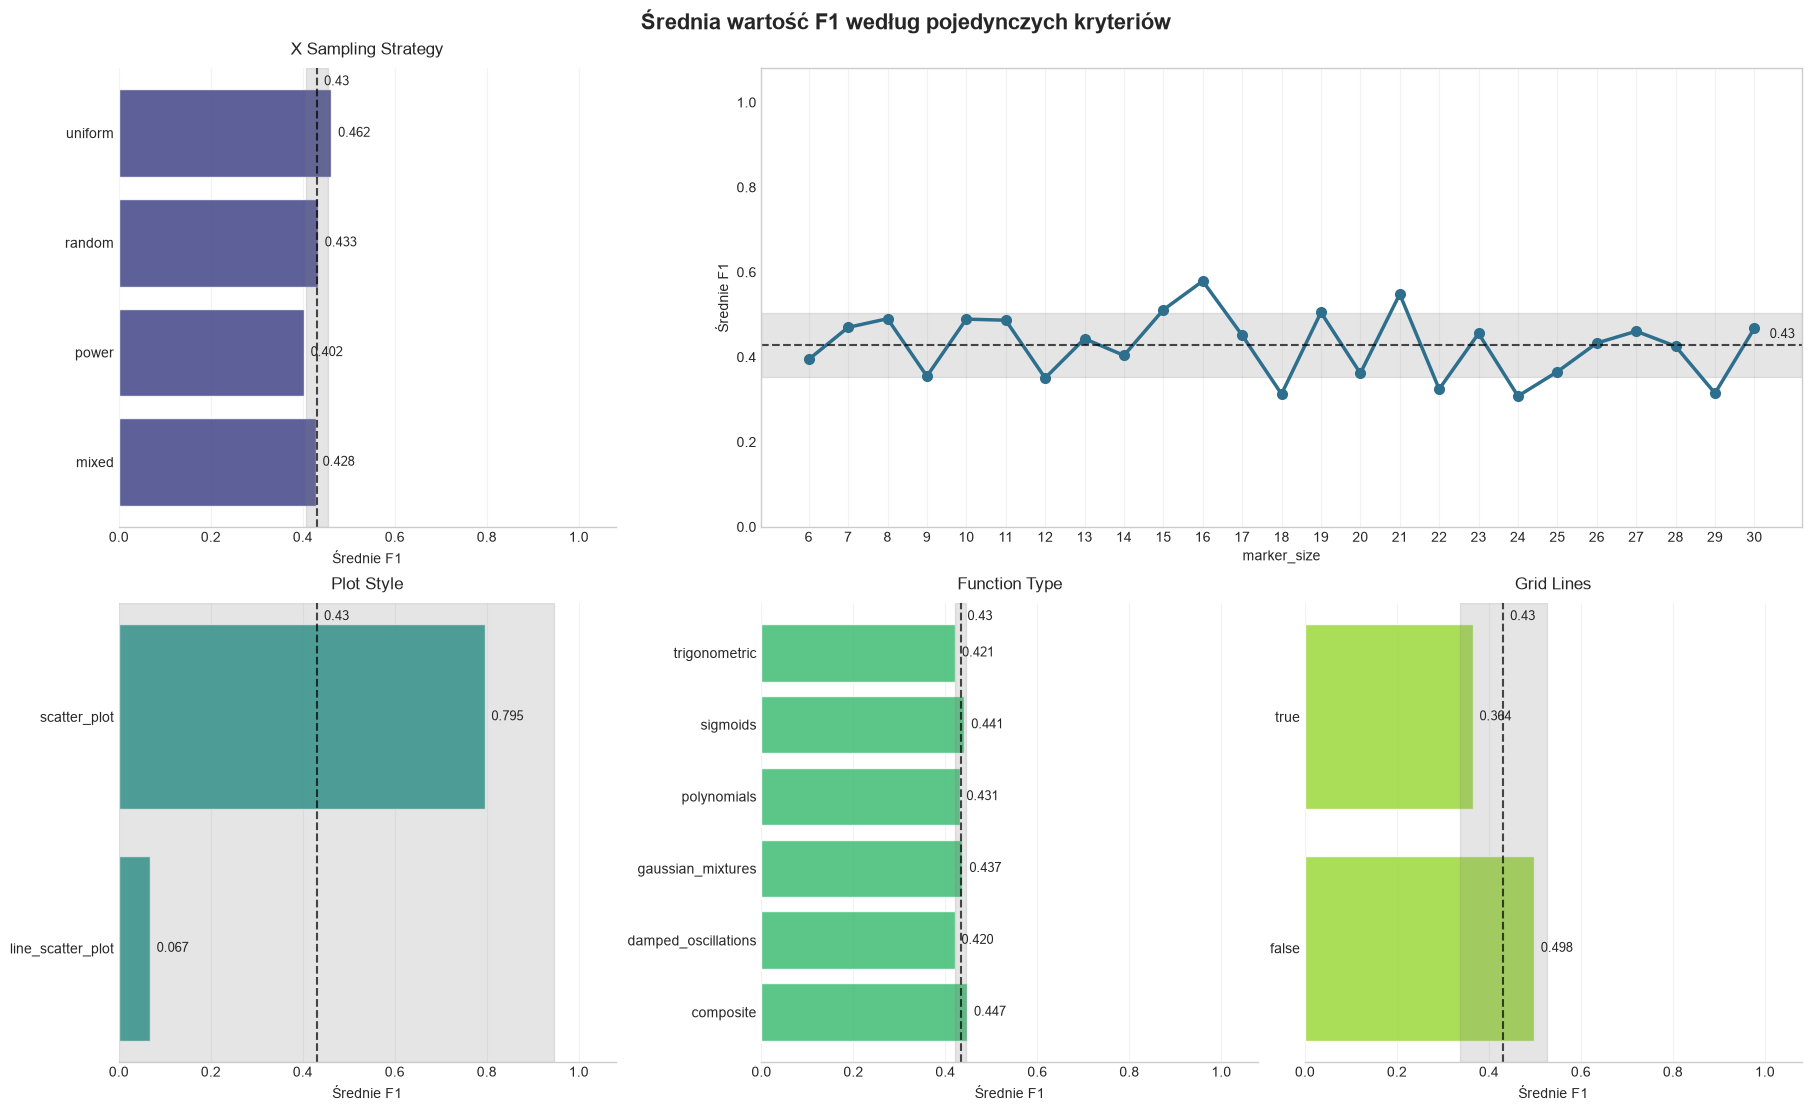

In [4]:
plot_mean_f1_by_grouping_column(baseline_results)

#### Najważniejsze obserwacje

- Strategia próbkowania punktów na osi X ma niewielki wpływ na skuteczność detekcji. Wyniki skupiają się wokół F1 ≈ 0,43, a strategia `power` wyraźniej odbiega od pozostałych.
- Wpływ `marker_size` jest na ogół stabilny, choć dla niektórych rozmiarów pojawiają się wyraźne odchylenia od średniej.
- Typ funkcji ma niewielki wpływ na wynik; wartości F1 charakteryzują się małym rozrzutem.
- Obecność linii siatki obniża skuteczność metody bazowej, ponieważ dodatkowe struktury są traktowane jako elementy obrazu.
- Największą różnicę widać między wykresami punktowymi i punktowo-liniowymi.

### 3.2. Wyniki dla wykresów punktowych

In [5]:
baseline_scatter_results = baseline_results.filter(
    pl.col("plot_style") == "scatter_plot"
)

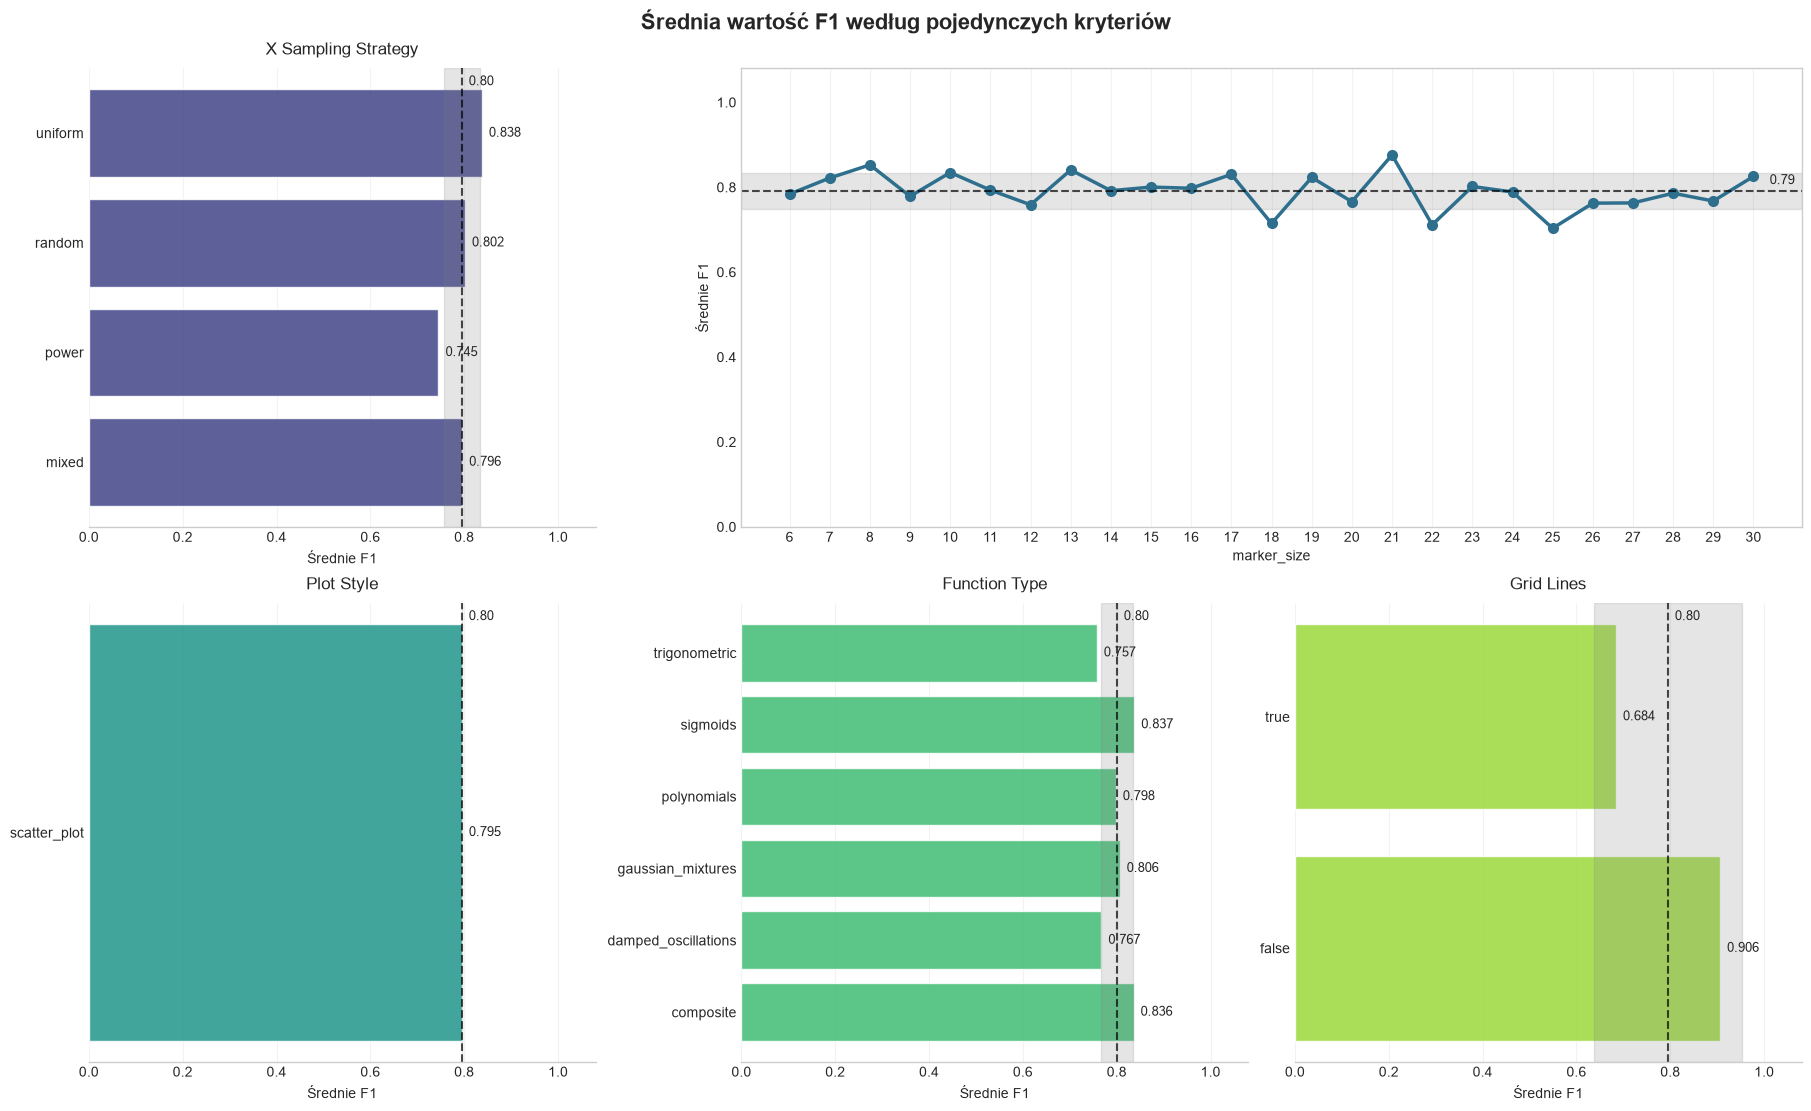

In [6]:
plot_mean_f1_by_grouping_column(baseline_scatter_results)

#### Wnioski

- Średnie wartości F1 są wyraźnie wyższe niż w analizie obejmującej oba typy wykresów.
- Strategia próbkowania osi X nadal ma niewielkie znaczenie; wyjątkiem jest `power`, która daje średnio słabsze wyniki.
- Zależność F1 od `marker_size` jest bardziej stabilna.
- Najniższą skuteczność obserwujemy dla `trigonometric` i `damped_oscillation`.
- Linie siatki nadal obniżają skuteczność detekcji.

### 3.3. Wyniki dla wykresów punktowo-liniowych

In [7]:
baseline_line_scatter_results = baseline_results.filter(
    pl.col("plot_style") == "line_scatter_plot"
)

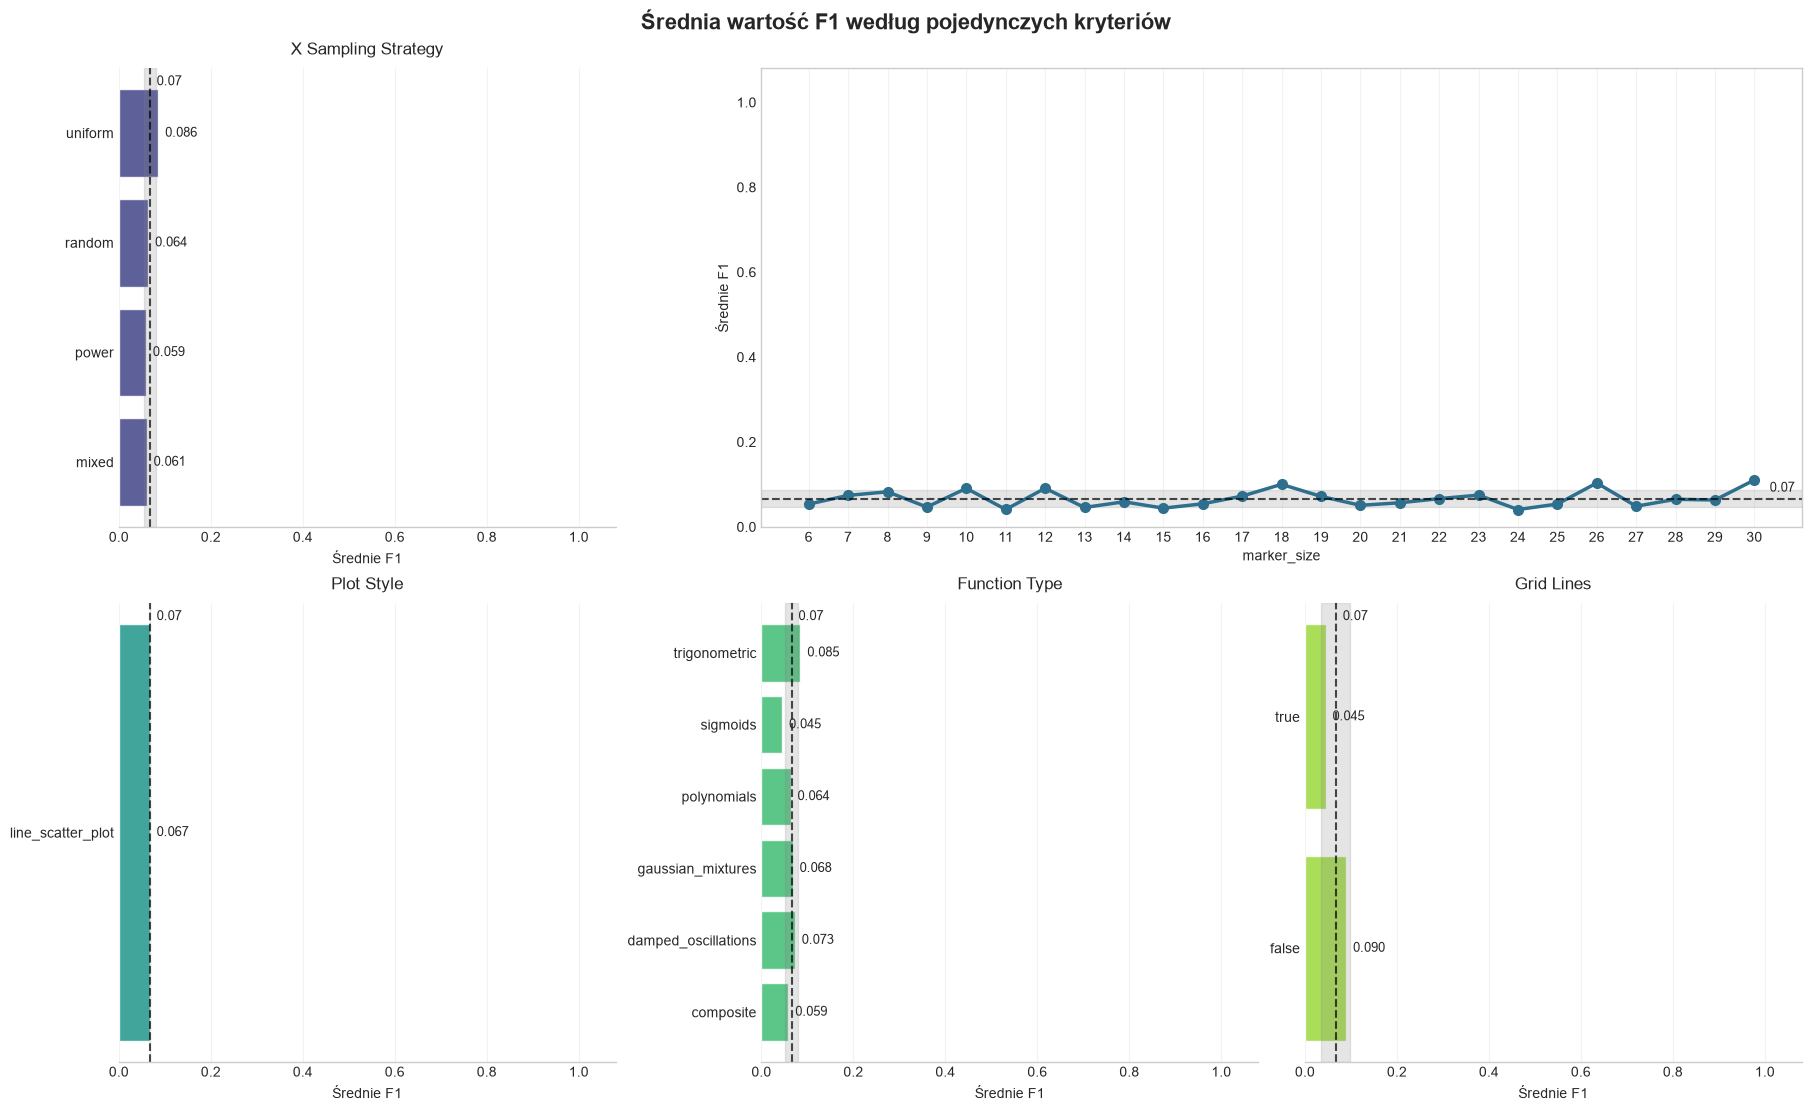

In [8]:
plot_mean_f1_by_grouping_column(baseline_line_scatter_results)

#### Wnioski

- Skuteczność metody bazowej jest bardzo niska we wszystkich analizowanych grupach.
- Linie łączące punkty łączą się z markerami w obrazie binarnym, przez co utrudniają poprawne wyodrębnienie pojedynczych punktów.
- Wykresy sigmoidalne są szczególnie trudne do analizy w tej konfiguracji.

## 4. Metoda `line_aware`

Metoda `line_aware` wykorzystuje transformację odległości:

1. tworzy maskę foregroundu,
2. oblicza odległość każdego piksela foregroundu od tła,
3. odrzuca cienkie struktury, takie jak linie łączące,
4. analizuje pozostałe rdzenie markerów jako potencjalne punkty.

In [9]:
line_aware_results = image_summary.filter(
    pl.col("detection_method") == "line_aware"
)

### 4.1. Wyniki zbiorcze

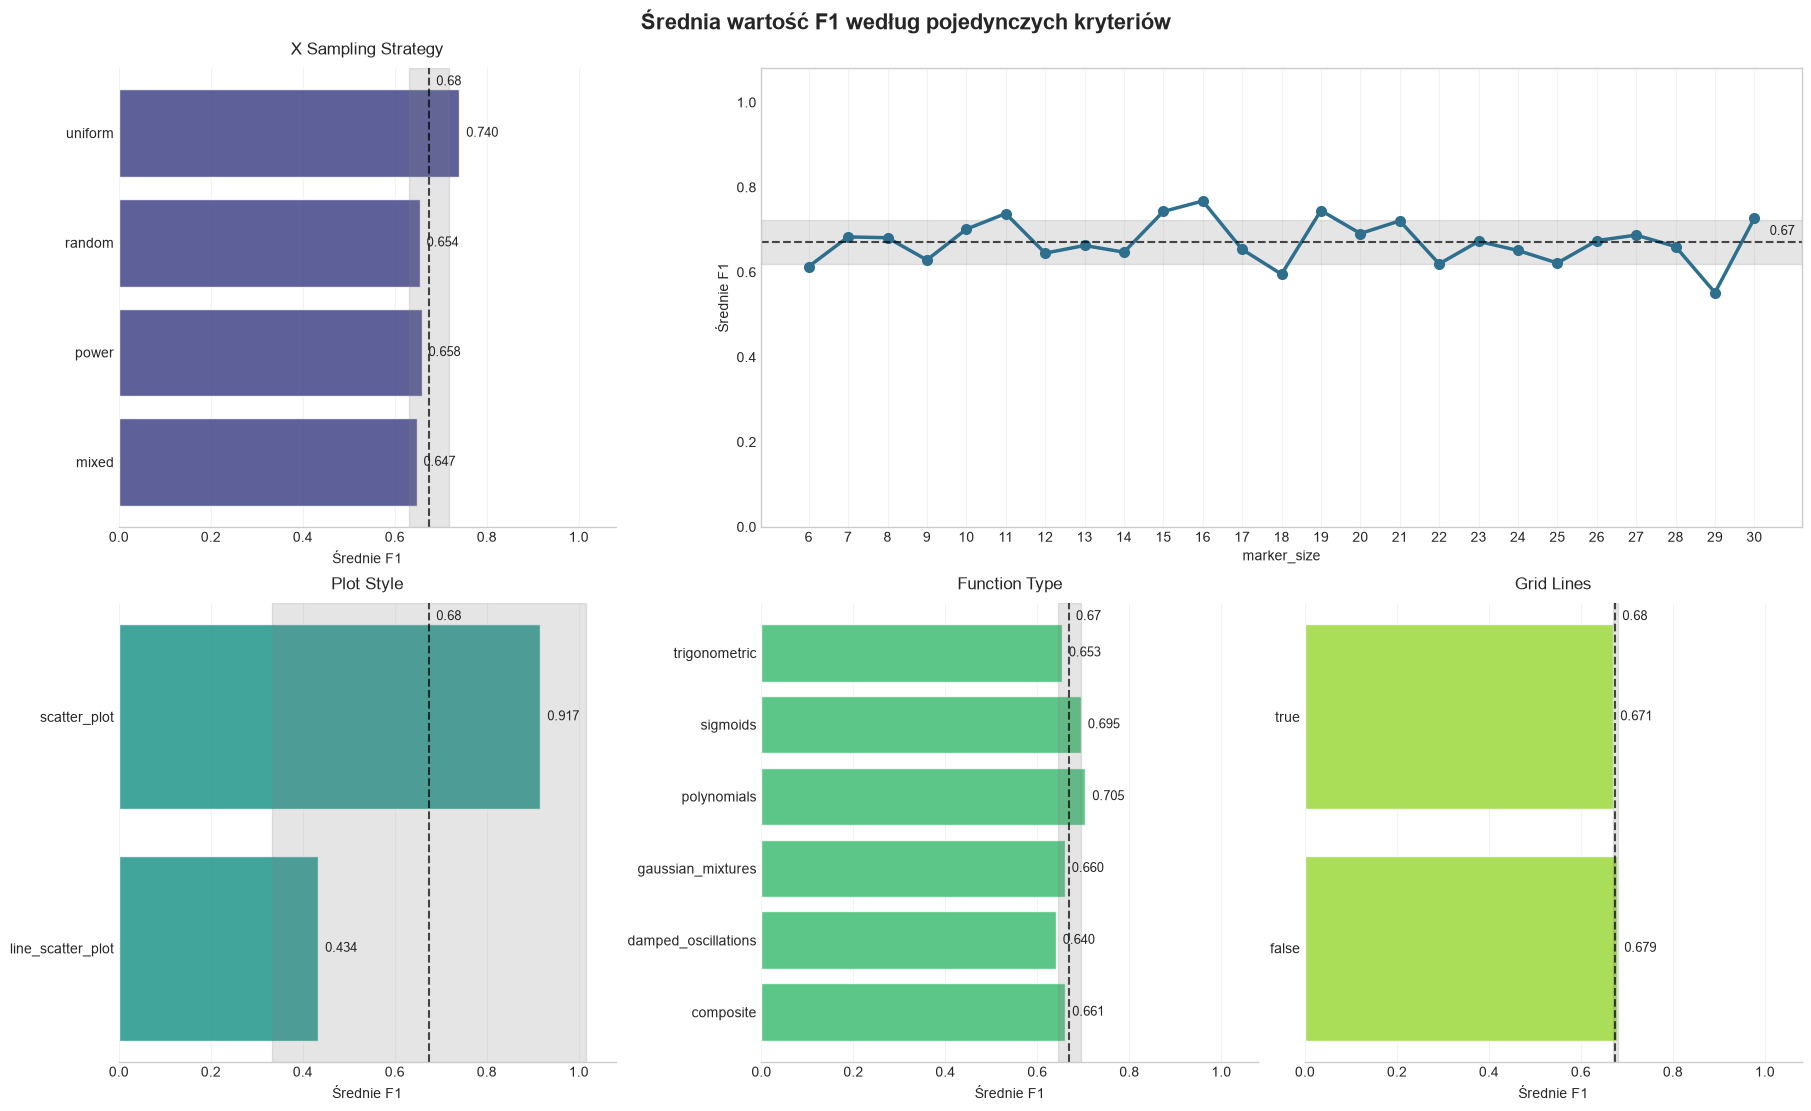

In [10]:
plot_mean_f1_by_grouping_column(line_aware_results)

#### Najważniejsze obserwacje

- Strategia `uniform` osiąga najwyższe wartości F1 spośród strategii próbkowania osi X.
- Linie siatki mają mniejszy wpływ niż w przypadku metody bazowej.
- Najważniejszym testem pozostają wykresy punktowo-liniowe, dla których metoda została zaprojektowana.

### 4.2. Wyniki dla wykresów punktowych

In [11]:
line_aware_scatter_results = line_aware_results.filter(
    pl.col("plot_style") == "scatter_plot"
)
line_aware_line_scatter_results = line_aware_results.filter(
    pl.col("plot_style") == "line_scatter_plot"
)

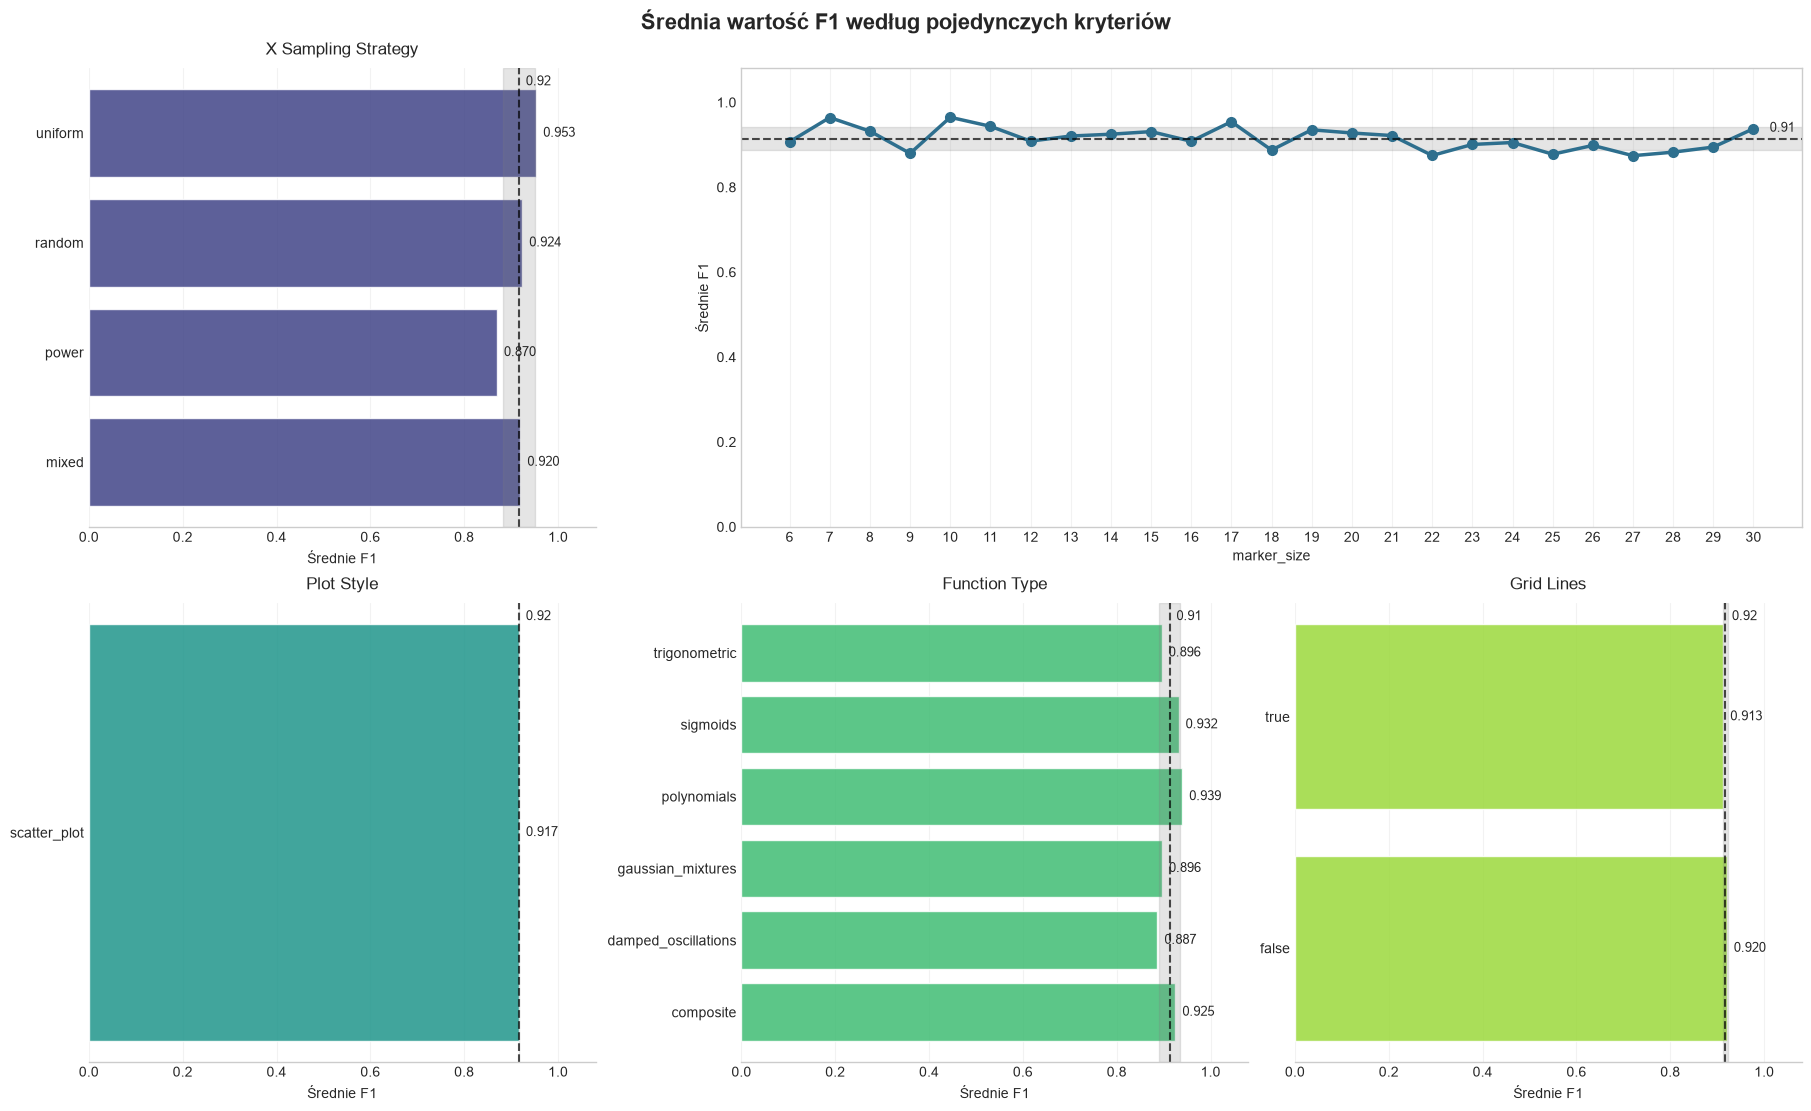

In [12]:
plot_mean_f1_by_grouping_column(line_aware_scatter_results)

#### Porównanie z metodą bazową

- Metoda `line_aware` poprawia średnią skuteczność w większości grup.
- Różnice są mniejsze niż dla wykresów punktowo-liniowych.
- Dodatkowe przetwarzanie nie daje istotnej przewagi na obrazach, na których nie występują linie łączące punkty.

### 4.3. Wyniki dla wykresów punktowo-liniowych

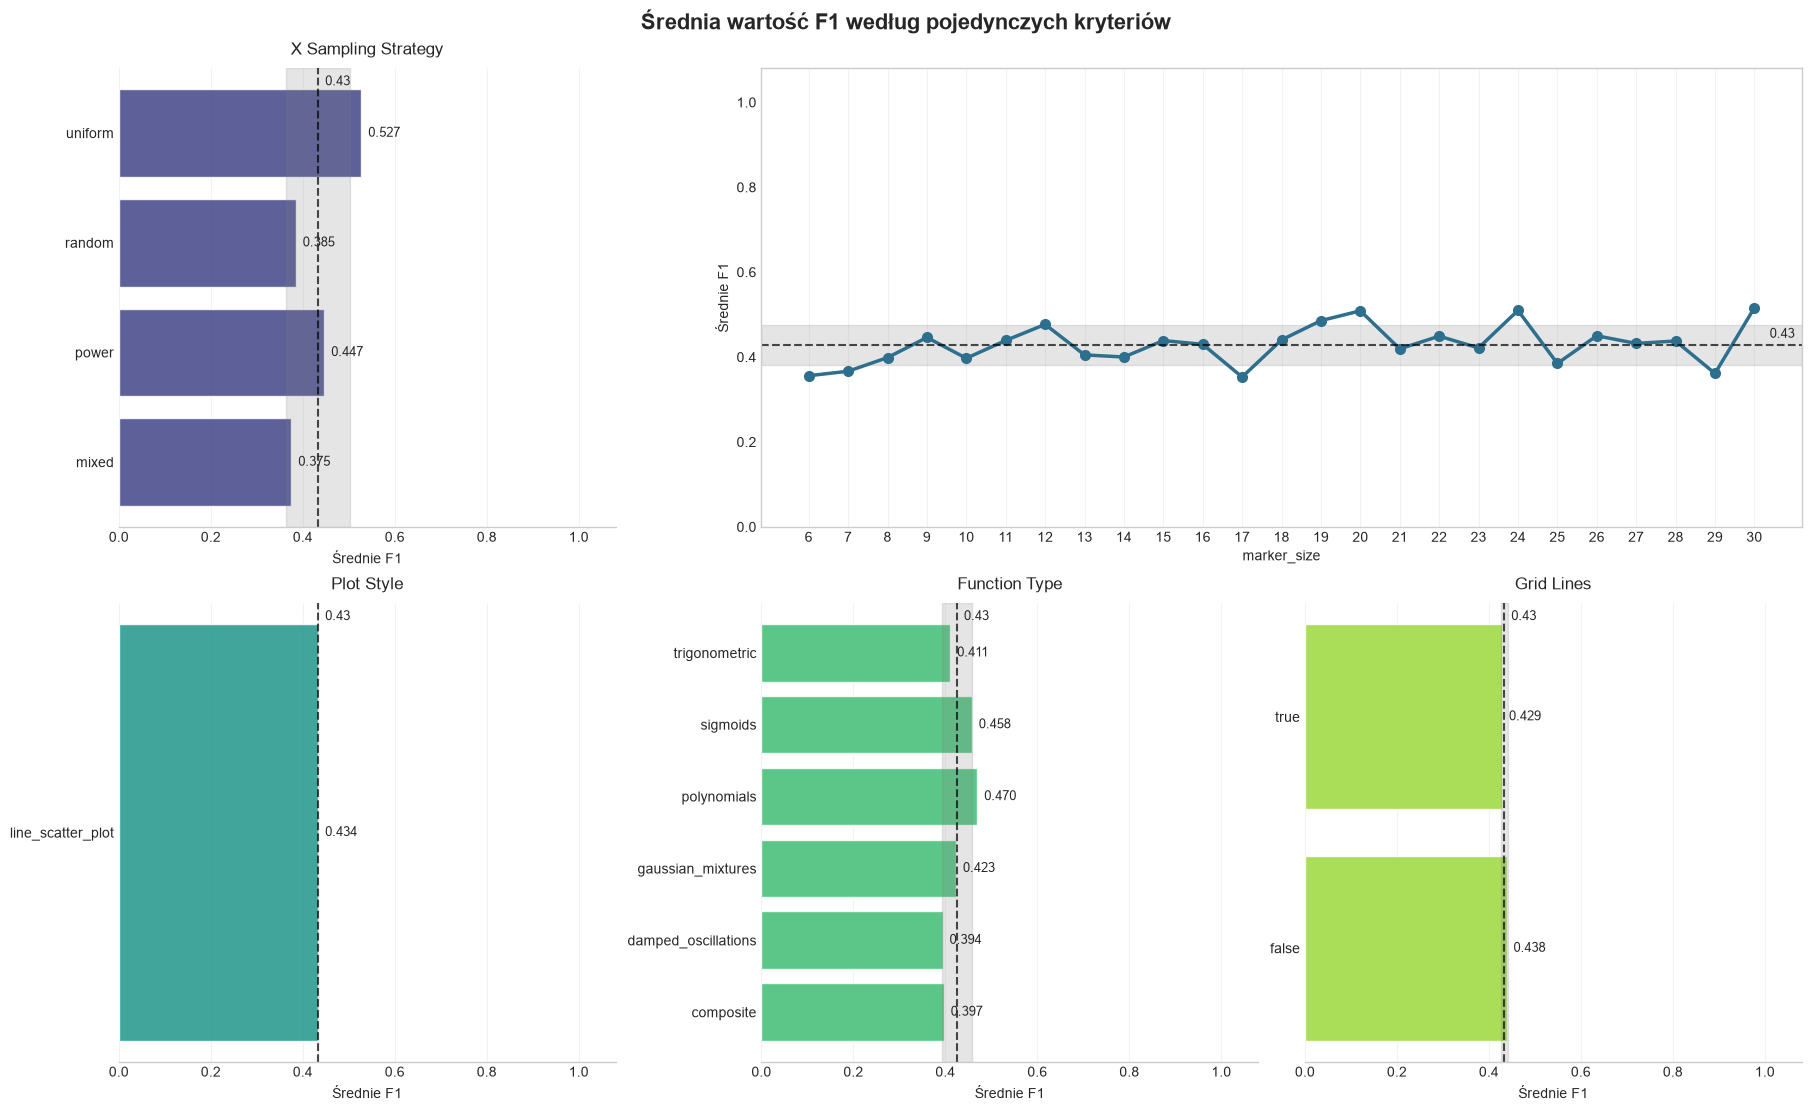

In [13]:
plot_mean_f1_by_grouping_column(line_aware_line_scatter_results)

#### Porównanie z metodą bazową

- Średnia wartość F1 wzrasta z około 0,07 do około 0,43.
- Metoda `line_aware` wyraźnie ogranicza negatywny wpływ linii łączących punkty.
- Jest to najważniejszy przypadek użycia tej metody i największa różnica względem rozwiązania bazowego.